In [ ]:
# Final Project: Gun Violence Challenge
# Authors: Nicolas Angulo and Andres Martinez
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Dataset location in Google Colab
DATA_PATH = Path("/content/updated_with_coordinates.csv")

# Load the dataset
gun_data = pd.read_csv(DATA_PATH)

print("Dataset shape:", gun_data.shape)

print("\nFirst five records:")
display(gun_data.head())

print("\nDataset information:")
gun_data.info()

print("\nMissing values:")
print(gun_data.isnull().sum())


Dataset shape: (427, 14)

First five records:


,Incident ID,Incident Date,State,City Or County,Address,Victims Killed,Victims Injured,Suspects Killed,Suspects Injured,Suspects Arrested,Operations,Latitude,Longitude,Coordinates_Found
0,3052758,"October 21, 2024",Washington,Fall City,7700 block of Lake Alice Rd SE,5,1,0,0,1,NaN,47.56812,-121.89086,Yes
1,3052028,"October 20, 2024",Tennessee,Jackson,2310 N Highland Ave,1,8,0,0,0,NaN,35.61390,-88.81940,Yes
2,3051984,"October 20, 2024",Louisiana,Baton Rouge,9700 block of Greenwell Springs Rd,0,5,0,0,0,NaN,30.44335,-91.18664,Yes
3,3051041,"October 19, 2024",Pennsylvania,Philadelphia,2517 N Jessup St,0,7,0,0,0,NaN,39.95222,-75.16218,Yes
4,3050940,"October 19, 2024",Mississippi,Lexington,24904 MS-17,3,8,0,0,0,NaN,33.11464,-90.05281,Yes



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 427 entries, 0 to 426
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Incident ID        427 non-null    int64  
 1   Incident Date      427 non-null    object 
 2   State              427 non-null    object 
 3   City Or County     427 non-null    object 
 4   Address            426 non-null    object 
 5   Victims Killed     427 non-null    int64  
 6   Victims Injured    427 non-null    int64  
 7   Suspects Killed    427 non-null    int64  
 8   Suspects Injured   427 non-null    int64  
 9   Suspects Arrested  427 non-null    int64  
 10  Operations         0 non-null      float64
 11  Latitude           427 non-null    float64
 12  Longitude          427 non-null    float64
 13  Coordinates_Found  427 non-null    object 
dtypes: float64(3), int64(6), object(5)
memory usage: 46.8+ KB

Missing values:
Incident ID            0


In [ ]:
#lists out all the columns in the dataset to help us explain in the presentation
gun_data.columns

Index(['Incident ID', 'Incident Date', 'State', 'City Or County', 'Address',
       'Victims Killed', 'Victims Injured', 'Suspects Killed',
       'Suspects Injured', 'Suspects Arrested', 'Operations', 'Latitude',
       'Longitude', 'Coordinates_Found'],
      dtype='object')

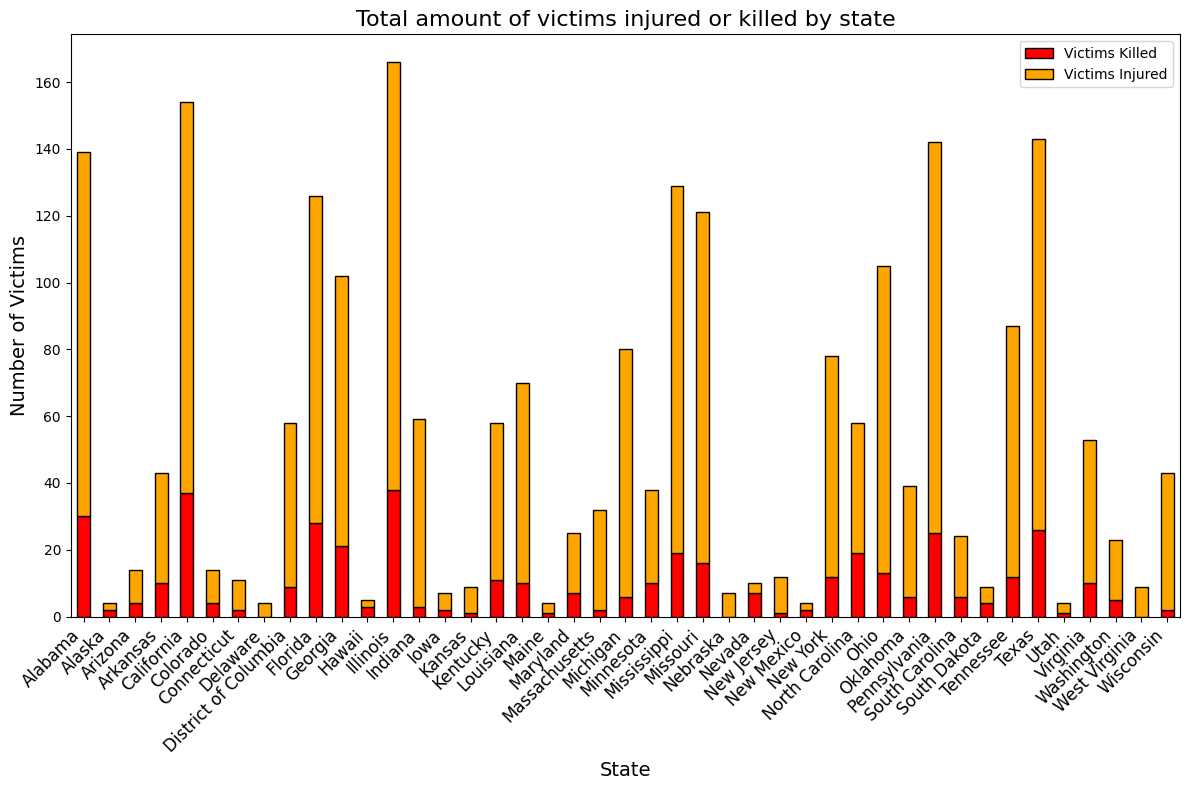

In [ ]:
#For this graph we want to show the total amount of victims either killed or injured per state
vitims_per_state = gun_data.groupby('State')[['Victims Killed', 'Victims Injured']].sum()

plt.figure(figsize=(12, 8))
vitims_per_state.plot(kind='bar', stacked=True, color=['red', 'orange'], edgecolor='black', ax=plt.gca())

plt.title('Total amount of victims injured or killed by state', fontsize=16)
plt.xlabel('State', fontsize=14)
plt.ylabel('Number of Victims', fontsize=14)
plt.xticks(rotation=45, ha='right', fontsize=12)

plt.tight_layout()
plt.show()

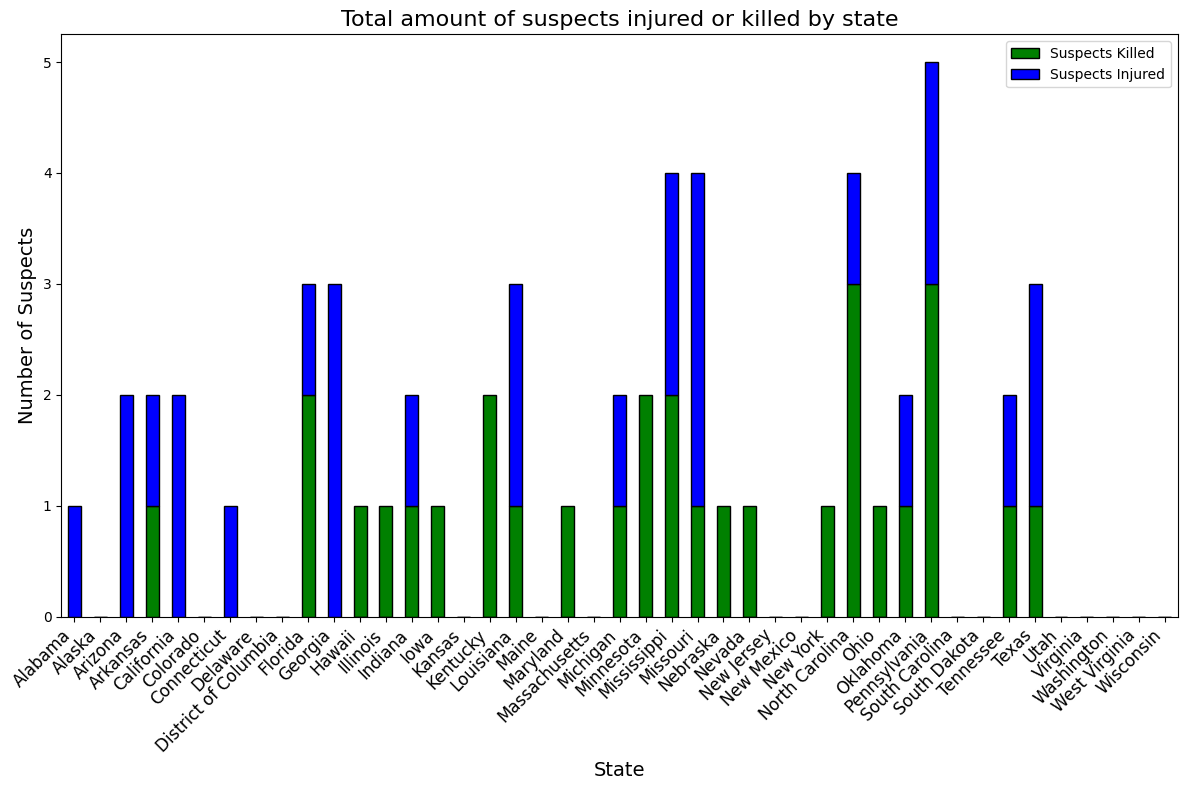

In [ ]:
#similar to the graph above this graph will display the amount of suspects that were either injured or killed per states
suspectVictimData = gun_data.groupby('State')[['Suspects Killed', 'Suspects Injured']].sum()

plt.figure(figsize=(12, 8))
suspectVictimData.plot(kind='bar', stacked=True, color=['green', 'blue'], edgecolor='black', ax=plt.gca())

plt.title('Total amount of suspects injured or killed by state', fontsize=16)
plt.xlabel('State', fontsize=14)
plt.ylabel('Number of Suspects', fontsize=14)
plt.xticks(rotation=45, ha='right', fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
#This portion will help us identify each unique class
#In this case all the unique classes are states
labelColumn = 'State'

uniqueClass = gun_data[labelColumn].unique()
numberClasses = len(uniqueClass)

print("Amount of unique classes: ")
print(uniqueClass)

Amount of unique classes: 
['Washington' 'Tennessee' 'Louisiana' 'Pennsylvania' 'Mississippi'
 'Georgia' 'Indiana' 'Michigan' 'Oklahoma' 'Ohio' 'South Carolina'
 'Missouri' 'Texas' 'California' 'Virginia' 'District of Columbia'
 'North Carolina' 'Illinois' 'Minnesota' 'New York' 'Arizona' 'Alabama'
 'Kentucky' 'Florida' 'New Jersey' 'Delaware' 'Hawaii' 'South Dakota'
 'Wisconsin' 'Maryland' 'Massachusetts' 'Colorado' 'West Virginia' 'Maine'
 'Connecticut' 'Kansas' 'Nebraska' 'Nevada' 'Arkansas' 'Utah' 'New Mexico'
 'Alaska' 'Iowa']


In [ ]:
#This is to show what features contian null variables
gun_data.isnull().sum()

,0
Incident ID,0
Incident Date,0
State,0
City Or County,0
Address,1
Victims Killed,0
Victims Injured,0
Suspects Killed,0
Suspects Injured,0
Suspects Arrested,0


In [ ]:
# Map each U.S. state to its corresponding geographic region.
# The four regions are Northeast, Midwest, South, and West.

state_to_region = {
    'Northeast': [
        'Connecticut', 'Maine', 'Massachusetts',
        'New Hampshire', 'Rhode Island', 'Vermont',
        'New Jersey', 'New York', 'Pennsylvania'
    ],
    'Midwest': [
        'Indiana', 'Illinois', 'Iowa', 'Kansas',
        'Michigan', 'Minnesota', 'Missouri',
        'Nebraska', 'North Dakota', 'Ohio',
        'South Dakota', 'Wisconsin'
    ],
    'South': [
        'Alabama', 'Arkansas', 'Delaware',
        'Florida', 'District of Coumbia', 'Georgia', 'Kentucky',
        'Louisiana', 'Maryland', 'Mississippi',
        'North Carolina', 'Oklahoma',
        'South Carolina', 'Tennessee', 'Texas',
        'Virginia', 'West Virginia'
    ],
    'West': [
        'Alaska', 'Arizona', 'California',
        'Colorado', 'Hawaii', 'Idaho',
        'Montana', 'Nevada', 'New Mexico',
        'Oregon', 'Utah', 'Washington', 'Wyoming'
    ]
}

# Create a reverse mapping from states to regions
region_mapping = {
    state: region
    for region, states in state_to_region.items()
    for state in states
}

# Assign each state its corresponding region
gun_data["Region"] = gun_data["State"].map(region_mapping)

# Display the number of records in each region
print("Incidents by Region:")
print(gun_data["Region"].value_counts())

# Check for states that were not successfully mapped
unmapped_states = gun_data.loc[
    gun_data["Region"].isna(), "State"
].unique()

print("\nUnmapped States:", unmapped_states)



Incidents by Region:
Region
South        203
Midwest      112
Northeast     55
West          45
Name: count, dtype: int64

Unmapped States: ['District of Columbia']


In [ ]:
# Select relevant columns for descriptive analysis
data_columns = [
    "State",
    "Victims Killed",
    "Victims Injured",
    "Latitude",
    "Longitude"
]

data = gun_data[data_columns].copy()

# Calculate total victims for each incident
data["Total Victims"] = (
    data["Victims Killed"] + data["Victims Injured"]
)

# Aggregate victim totals by state
state_aggregated = (
    data.groupby("State")["Total Victims"]
    .sum()
    .reset_index()
)

display(state_aggregated.head())


,State,Total Victims
0,Alabama,139
1,Alaska,4
2,Arizona,14
3,Arkansas,43
4,California,154


In [ ]:
#shows summary stats for the victims affected (injured or killed)
#NOTE: We were not able to calculate for covarience due to the fact the we are dealing with
summaryStats = data.describe()
print('Summary Statistics:')
print(summaryStats)

Summary Statistics:
       Victims Killed  Victims Injured    Latitude   Longitude  Total Victims
count      427.000000       427.000000  427.000000  427.000000     427.000000
mean         1.000000         4.437939   36.941819  -88.791959       5.437939
std          1.210285         2.849555    4.934289   12.976850       2.780341
min          0.000000         0.000000   21.449910 -166.739450       3.000000
25%          0.000000         3.000000   33.449545  -91.910580       4.000000
50%          1.000000         4.000000   37.687490  -86.811790       4.000000
75%          1.000000         5.000000   40.692450  -80.735325       6.000000
max          8.000000        28.000000   68.349440  -70.256650      29.000000


In [ ]:
#Here i used an outside source to help properly aggregate the data
#source: https://www.geeksforgeeks.org/python-pandas-dataframe-aggregate/
#Because we are looking at the data at a general regional pov it would be better help to the trianing and data visualization to aggregate the data
state_aggregated['Region'] = state_aggregated['State'].map(region_mapping)

region_aggregated = state_aggregated.groupby('Region')['Total Victims'].sum().reset_index()


In [ ]:
#Anywhere from 0-100 victims would be low frequency, 101-300, would be considered medium frequency, an 301+ woul dbe considered high frequency
bins = [0, 100, 300, float('inf')]
labels = ['Low', 'Medium', 'High']
region_aggregated['Frequency Category'] = pd.cut(region_aggregated['Total Victims'], bins=bins, labels=labels)

In [ ]:
from sklearn.model_selection import train_test_split

# Create a separate dataset for the decision tree
decision_tree_data = gun_data.copy()

# Remove records missing required information
decision_tree_data = decision_tree_data.dropna(
    subset=[
        "Latitude",
        "Longitude",
        "Victims Killed"
    ]
)

# Define target:
# 0 = No recorded victim fatalities
# 1 = At least one recorded victim fatality
decision_tree_data["Fatal Incident"] = (
    decision_tree_data["Victims Killed"] > 0
).astype(int)

# Use geographic coordinates as baseline predictors
dt_features = ["Latitude", "Longitude"]

X_dt = decision_tree_data[dt_features]
y_dt = decision_tree_data["Fatal Incident"]

print("Target distribution:")
print(y_dt.value_counts())

# Split the dataset into training and testing sets
X_dt_train, X_dt_test, y_dt_train, y_dt_test = (
    train_test_split(
        X_dt,
        y_dt,
        test_size=0.2,
        random_state=42,
        stratify=y_dt
    )
)

print("Training records:", len(X_dt_train))
print("Testing records:", len(X_dt_test))


Target distribution:
Fatal Incident
1    246
0    181
Name: count, dtype: int64
Training records: 341
Testing records: 86


In [ ]:
#Here we start to create the decision tree
from sklearn.tree import DecisionTreeClassifier

# Initialize the decision tree classifier
clf = DecisionTreeClassifier(
    max_depth=4, #Placed a limit on how deep the decision tree can grow
    min_samples_leaf=5, #Requires at least five training samples for each leaf
    random_state=42
)

# Train the model
clf.fit(X_dt_train, y_dt_train)

# Make predictions
y_dt_pred = clf.predict(X_dt_test)

print("Decision tree training completed.")

Decision tree training completed.


In [ ]:
#Helps vizualize the data on the decision tree
from sklearn.tree import export_graphviz
import graphviz
# Export the trained decision tree
tree_data = export_graphviz(
    clf,
    out_file=None,
    feature_names=dt_features,
    class_names=["Nonfatal", "Fatal"],
    filled=True,
    rounded=True,
    special_characters=True
)

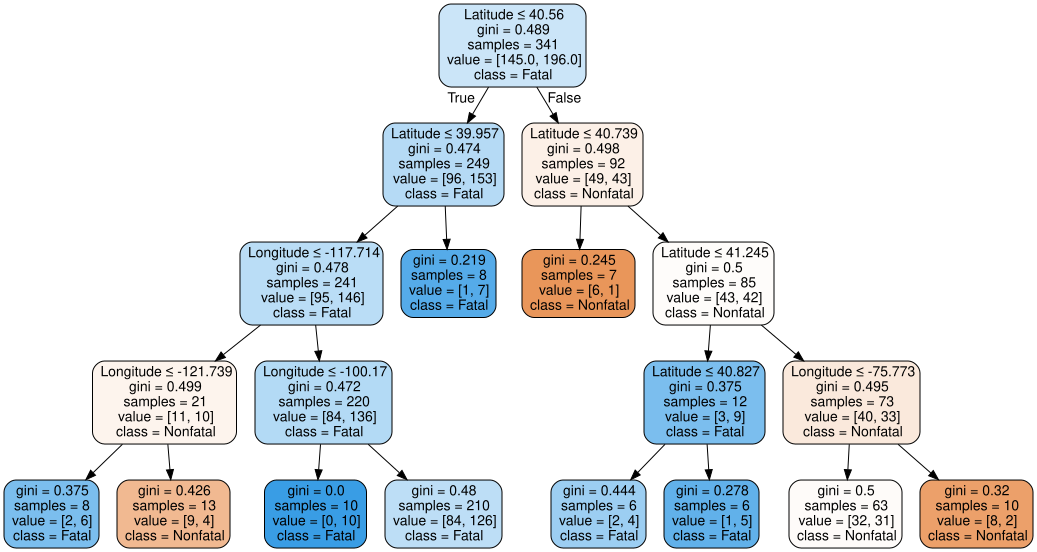

In [ ]:
# Display the decision tree
graph = graphviz.Source(tree_data)
display(graph)

In [ ]:
# Evaluate the decision tree using training accuracy,
# testing accuracy, precision, recall, and F1-score.
# Performance will be compared against a baseline classifier.
from sklearn.metrics import (
    accuracy_score,
    classification_report
)

# Evaluate training and testing accuracy
train_accuracy = clf.score(X_dt_train, y_dt_train)
test_accuracy = accuracy_score(y_dt_test, y_dt_pred)

print("Decision Tree Training Accuracy:", train_accuracy)
print("Decision Tree Testing Accuracy:", test_accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_dt_test,
        y_dt_pred,
        target_names=["Nonfatal", "Fatal"],
        zero_division=0
    )
)

Decision Tree Training Accuracy: 0.624633431085044
Decision Tree Testing Accuracy: 0.5581395348837209

Classification Report:
              precision    recall  f1-score   support

    Nonfatal       0.45      0.28      0.34        36
       Fatal       0.59      0.76      0.67        50

    accuracy                           0.56        86
   macro avg       0.52      0.52      0.51        86
weighted avg       0.54      0.56      0.53        86



In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

# Create a baseline model that predicts the most common class
baseline_model = DummyClassifier(
    strategy="most_frequent"
)

# Train the baseline model
baseline_model.fit(X_dt_train, y_dt_train)

# Generate predictions
baseline_predictions = baseline_model.predict(X_dt_test)

# Calculate baseline performance
baseline_accuracy = accuracy_score(
    y_dt_test, baseline_predictions
)

baseline_f1 = f1_score(
    y_dt_test, baseline_predictions,
    zero_division=0
)

# Compare the baseline and decision tree
dt_comparison = pd.DataFrame({
    "Model": ["Baseline", "Decision Tree"],
    "Accuracy": [
        baseline_accuracy,
        test_accuracy
    ],
    "Fatal F1-Score": [
        baseline_f1,
        f1_score(y_dt_test, y_dt_pred)
    ]
})

display(dt_comparison.round(4))

,Model,Accuracy,Fatal F1-Score
0,Baseline,0.5814,0.7353
1,Decision Tree,0.5581,0.6667


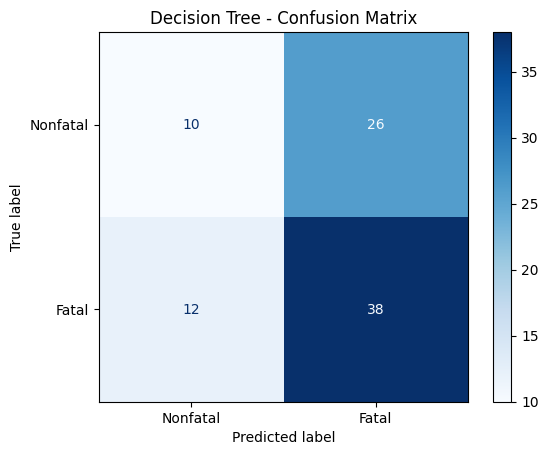

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

# Visualize model predictions
ConfusionMatrixDisplay.from_predictions(
    y_dt_test,
    y_dt_pred,
    display_labels=["Nonfatal", "Fatal"],
    cmap="Blues"
)

plt.title("Decision Tree - Confusion Matrix")
plt.show()


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Create a separate dataset for geographic classification without modifying the original DataFrame
geo_data = gun_data.dropna(
    subset=["Latitude", "Longitude", "Region"]
).copy()

# Select the geographic coordinates as features
X_geo = geo_data[["Latitude", "Longitude"]]

# Define the target variable (geographic region)
y_geo = geo_data["Region"]

# Split the dataset into training and testing sets
X_geo_train, X_geo_test, y_geo_train, y_geo_test = (
    train_test_split(
        X_geo,
        y_geo,
        test_size=0.2,
        random_state=42,
        stratify=y_geo
    )
)

# Create KNN and SVM models with feature scaling
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear")
)

# Train both models
knn_model.fit(X_geo_train, y_geo_train)
svm_model.fit(X_geo_train, y_geo_train)

# Generate predictions
knn_predictions = knn_model.predict(X_geo_test)
svm_predictions = svm_model.predict(X_geo_test)

# Calculate model accuracy
knn_accuracy = accuracy_score(
    y_geo_test, knn_predictions
)

svm_accuracy = accuracy_score(
    y_geo_test, svm_predictions
)

# Display results
print("KNN Accuracy:", knn_accuracy)
print("SVM Accuracy:", svm_accuracy)

print("\nKNN Classification Report:")
print(
    classification_report(
        y_geo_test,
        knn_predictions,
        zero_division=0
    )
)

print("\nSVM Classification Report:")
print(
    classification_report(
        y_geo_test,
        svm_predictions,
        zero_division=0
    )
)

KNN Accuracy: 0.9879518072289156
SVM Accuracy: 0.9518072289156626

KNN Classification Report:
              precision    recall  f1-score   support

     Midwest       0.96      1.00      0.98        22
   Northeast       1.00      0.91      0.95        11
       South       1.00      1.00      1.00        41
        West       1.00      1.00      1.00         9

    accuracy                           0.99        83
   macro avg       0.99      0.98      0.98        83
weighted avg       0.99      0.99      0.99        83


SVM Classification Report:
              precision    recall  f1-score   support

     Midwest       0.92      1.00      0.96        22
   Northeast       0.82      0.82      0.82        11
       South       1.00      0.95      0.97        41
        West       1.00      1.00      1.00         9

    accuracy                           0.95        83
   macro avg       0.93      0.94      0.94        83
weighted avg       0.95      0.95      0.95        83



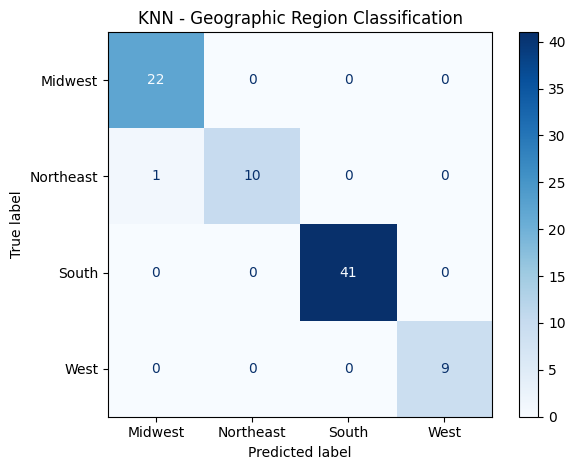

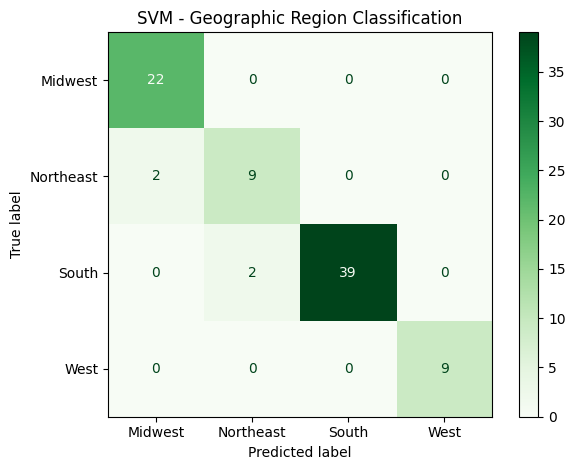

In [ ]:
import matplotlib.pyplot as plt

# Display the KNN confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_geo_test,
    knn_predictions,
    cmap="Blues"
)

plt.title("KNN - Geographic Region Classification")
plt.tight_layout()
plt.show()

# Display the SVM confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_geo_test,
    svm_predictions,
    cmap="Greens"
)

plt.title("SVM - Geographic Region Classification")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
# Compare the geographic classification models
geo_results = []

for name, predictions in [
    ("KNN", knn_predictions),
    ("SVM", svm_predictions)
]:
    geo_results.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_geo_test, predictions
        ),
        "Precision": precision_score(
            y_geo_test, predictions,
            average="weighted",
            zero_division=0
        ),
        "Recall": recall_score(
            y_geo_test, predictions,
            average="weighted",
            zero_division=0
        ),
        "F1-Score": f1_score(
            y_geo_test, predictions,
            average="weighted",
            zero_division=0
        )
    })

geo_comparison = pd.DataFrame(geo_results)

display(geo_comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,KNN,0.9880,0.9885,0.9880,0.9878
1,SVM,0.9518,0.9538,0.9518,0.9520


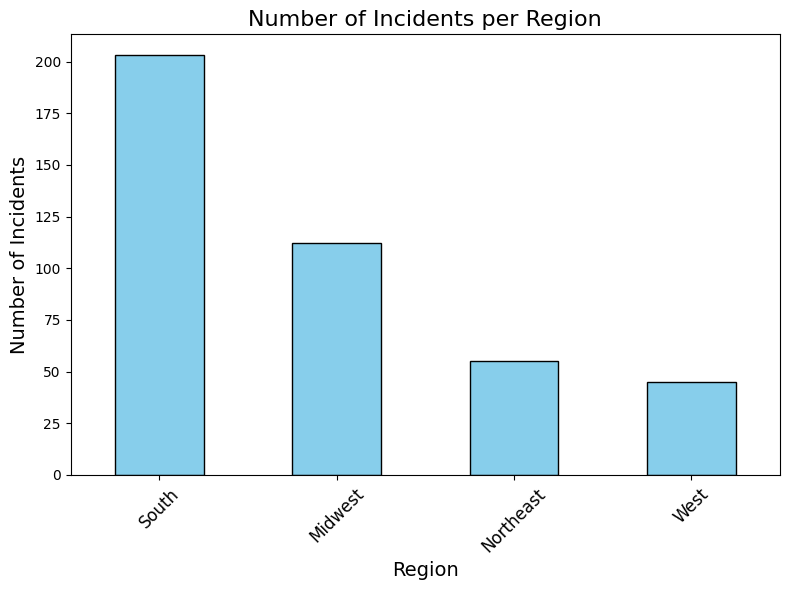

In [ ]:
#This is a chart that will help display the total amount of incidents per region
#helps support the challenge conclusion
regionCount = gun_data["Region"].value_counts()
regionCount.plot(kind='bar', color='skyblue', edgecolor='black', figsize=(8, 6))
plt.title('Number of Incidents per Region', fontsize=16)
plt.xlabel('Region', fontsize=14)
plt.ylabel('Number of Incidents', fontsize=14)
plt.xticks(rotation=45, fontsize=12)

plt.tight_layout()
plt.show()

**Model Evaluation and Results**

Three supervised machine learning algorithms were implemented to examine the classification performance across two different tasks.

The Decision Tree classifier was used to classify recorded incidents as fatal or nonfatal based on their geographical coordinates. The model achieved a testing accuracy of approximately 55.81%. To evaluate its effectiveness, its performance was compared against a majority-class baseline. The results indicate that geographic coordinates alone provide limited predictive information for this classification task.

The K-Nearest Neighbor (KNN) and Support Vector Machine (SVM) algorithms were used to classify incidents into geographic regions based on latitude and longitude. KNN achieved approximately 98.80% accuracy, while SVM achieved approximately 95.18% accuracy.

Although both models achieved high accuracy, this result is expected as the geographical regions are determined by location. Therefore, these results demonstrate the application of classification algorithms, rather than the ability to predict gun violence. Overall, this project demonstrates how different machine learning algorithms can be applied to structured datasets and highlights the importance of evaluating models beyond accuracy alone.